In [3]:
import os
class settings:
  def __init__(self):
    self.path1 = "experiment_icd"
    self.title1 = "(a) INA"
    self.dataset1 = "INA"
    self.dataset2 = "MIMIC"
    self.path2 = "experiment_icd"
    self.title2 = "(b) MIMIC-IV"
    self.iter=10

args = settings()

method_styles = {
    "STATIC": {"color": "#1f77b4", "linestyle": "-"},
    "STATIC+BINARY": {"color": "#ff7f0e", "linestyle": "-"},
    "STATIC+FREQUENCY": {"color": "#2ca02c", "linestyle": "--"},
    "STATIC+EVENT-CNT": {"color": "#ff7f0e", "linestyle": "--"},
    "STATIC+TF-IDF": {"color": "#8c564b", "linestyle": "--"},
    "STATIC+BOW": {"color": "#2ca02c", "linestyle": "-"},
    "STATIC+BiPadLSTM": {"color": "#d62728", "linestyle": "-"},
    "STATIC+Med2Vec": {"color": "#9467bd", "linestyle": "--"},
    "STATIC+Dipole": {"color": "#1f77b4", "linestyle": "--"},
    "STATIC+CEHR-BERT": {"color": "#9467bd", "linestyle": "-"},
    "STATIC+DOME": {"color":  "#8c564b", "linestyle": "-"},
    "STATIC+GRU": {"color": "#d62728", "linestyle": "--"},
}

## Radar plots

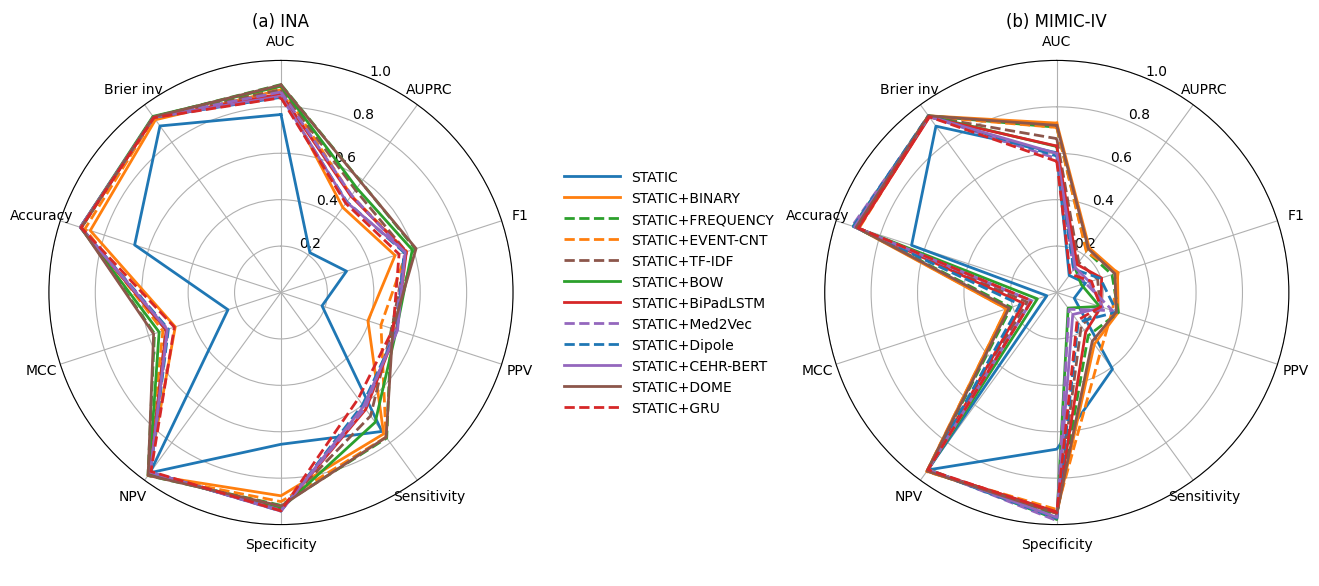

(<Figure size 1600x900 with 3 Axes>,
 [<PolarAxes: title={'center': '(a) INA'}>,
  <PolarAxes: title={'center': '(b) MIMIC-IV'}>])

In [4]:
from scripts.plotting import plot_radars
import pandas as pd
table1 = pd.read_csv(f"{args.path1}/result_table_{args.dataset1}_ITER{args.iter}.csv",index_col=0,).drop(columns=['Confusion matrix']).apply(lambda col: col.str[0:5])
table2 = pd.read_csv(f"{args.path2}/result_table_{args.dataset2}_ITER{args.iter}.csv",index_col=0,).drop(columns=['Confusion matrix']).apply(lambda col: col.str[0:5])
table1['Brier inv'] = table1['Brier'].apply(lambda x: f"{1-float(x)}")
table1.drop(columns=['Brier'], inplace=True)
table2['Brier inv'] = table2['Brier'].apply(lambda x: f"{1-float(x)}")
table2.drop(columns=['Brier'], inplace=True)
plot_radars(table1, table2, method_styles, titles=[args.title1, args.title2])